# code_045 · Temporal, spatial and relational patterns

**Book:** section 9.4. A self-contained exploration laboratory using invented building, load and sensor records. Prerequisites: arrays/tables and Chapter 8's case, timing and schema contracts. Restart and run all cells; all imports, helpers and generated inputs are here. Ordinary execution needs no files, network, keys, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_09_GUIDE.md), [execution evidence](../CHAPTER_09_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_045).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow one minute to run and 30–60 minutes to interpret. These scoped concept experiments disclose data/task controls rather than claim exhaustive estimator API coverage. Plots and construction identities are exploratory diagnostics, not independent predictive evidence. Only the hypothesis laboratory fits competing predictors, selects on development buildings and opens a protected final set after freezing its rule. All evidence is synthetic, with no structural-safety, population-calibration or causal claim.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=945;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 945


<a id="time"></a>
## Serial structure has more than one source

Generate 240 daily sensor measurements: a 24-day sinusoid plus a stationary AR(1) residual with phi=.75 and innovation sd .2 mm. Initial residual is sampled with stationary variance sigma²/(1-phi²). The seasonality is a simulator cycle, not claimed annual building behavior. Compute the mean-centered, fixed-denominator sample autocorrelation for lags 0–48. The oscillation and residual persistence can both produce structure; autocorrelation does not identify their physical cause. No independent-row confidence bands are drawn.


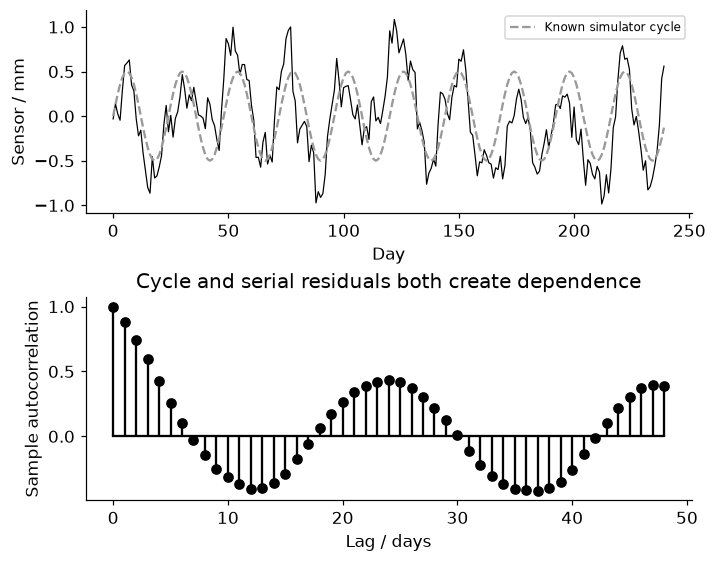

In [2]:
T=240;phi=.75;sigma=.2;t=np.arange(T);e=np.empty(T);e[0]=rng.normal(0,sigma/np.sqrt(1-phi*phi))
for j in range(1,T):e[j]=phi*e[j-1]+rng.normal(0,sigma)
season=.5*np.sin(2*np.pi*t/24);series=season+e
centered=series-series.mean();acf=np.array([centered[:T-k]@centered[k:]/(centered@centered) for k in range(49)])
assert np.isclose(acf[0],1) and np.isfinite(acf).all() and acf[1]>.4
fig,axes=plt.subplots(2,1,figsize=(6.4,5));axes[0].plot(t,series,'k-',lw=.8);axes[0].plot(t,season,color='.6',ls='--',label='Known simulator cycle');axes[0].set(xlabel='Day',ylabel='Sensor / mm');axes[0].legend(fontsize=8);axes[1].stem(np.arange(49),acf,linefmt='k-',markerfmt='ko',basefmt='k-');axes[1].set(xlabel='Lag / days',ylabel='Sample autocorrelation',title='Cycle and serial residuals both create dependence');plt.show()
RESULTS['sample_ACF_lags_1_12_24']={str(k):float(acf[k]) for k in [1,12,24]}


<a id="scales"></a>
## Nearby locations and connected members define other relationships

Six floor-plan locations have covariance exp(-distance/1.2) in normalized mm² units with .05 diagonal nugget. Draw 500 independent snapshots from this positive-definite Gaussian simulator and inspect empirical sensor correlations; spatial distance is not a prediction of causation. A separate physical member graph has component sizes 5,4,3. A random node split crosses physical links, while a component split may remove all cross-component links but still leave only three independent graph units. These are separate fixtures; the floor-plan covariance is not estimated from the member graph.


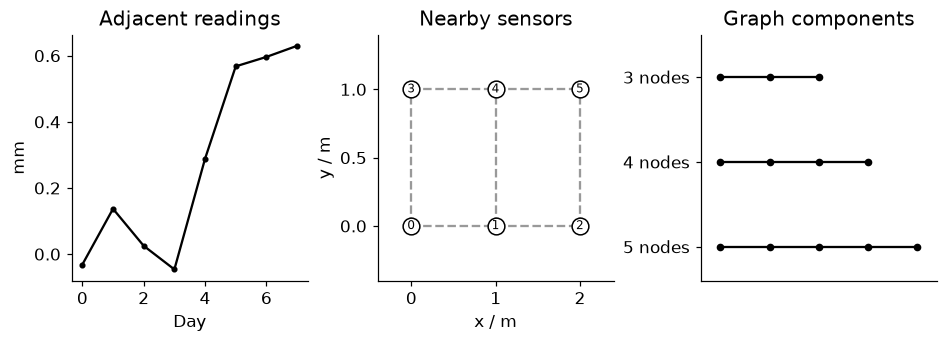

In [3]:
xy=np.array([[0,0],[1,0],[2,0],[0,1],[1,1],[2,1]],dtype=float);distance=np.sqrt(((xy[:,None]-xy[None,:])**2).sum(2));K=np.exp(-distance/1.2)+.05*np.eye(6)
assert np.linalg.eigvalsh(K).min()>0
snap=rng.multivariate_normal(np.zeros(6),K,size=500);corr=np.corrcoef(snap,rowvar=False)
near=corr[distance==1];far=corr[distance>2];assert near.mean()>far.mean()
edges=np.array([(i,i+1) for a,b in [(0,5),(5,9),(9,12)] for i in range(a,b-1)]);component=np.repeat([0,1,2],[5,4,3]);assert np.all(component[edges[:,0]]==component[edges[:,1]])
node_train=np.arange(12)%2==0;cross=int(np.sum(node_train[edges[:,0]]!=node_train[edges[:,1]]));assert cross>0
fig,axes=plt.subplots(1,3,figsize=(8.5,3))
axes[0].plot(np.arange(8),series[:8],'ko-',ms=3);axes[0].set(xlabel='Day',ylabel='mm',title='Adjacent readings')
for i in range(6):
 for j in range(i+1,6):
  if distance[i,j]==1:axes[1].plot(xy[[i,j],0],xy[[i,j],1],color='.6',ls='--')
axes[1].scatter(xy[:,0],xy[:,1],facecolors='white',edgecolors='black',s=120,zorder=3)
for j in range(6):axes[1].text(*xy[j],str(j),ha='center',va='center',fontsize=8)
axes[1].set(xlim=(-.4,2.4),ylim=(-.4,1.4),xlabel='x / m',ylabel='y / m',title='Nearby sensors')
for k,(start,size) in enumerate([(0,5),(5,4),(9,3)]):
 xx=np.arange(size);yy=np.full(size,k+.1);axes[2].plot(xx,yy,'ko-',ms=4)
axes[2].set(xlim=(-.4,4.4),ylim=(-.3,2.6),yticks=[.1,1.1,2.1],yticklabels=['5 nodes','4 nodes','3 nodes'],xticks=[],title='Graph components');plt.show()
RESULTS['empirical_near_sensor_correlation']=float(near.mean());RESULTS['empirical_far_sensor_correlation']=float(far.mean());RESULTS['component_sizes']=[5,4,3];RESULTS['random_node_split_cross_edges']=cross


<a id="independent"></a>
## Count effective evidence for a specified estimator

A separate random-intercept fixture has G=20 independent buildings, m=10 readings per building, between-building variance .8 mm² and within-building variance .2 mm². Marginal variance is 1 and same-building correlation rho=.8. For the grand mean with equal cluster sizes, its variance is 1*(1+(m-1)*rho)/(G*m)=.041 mm². Define an equivalent independent count for this mean as N_eff=N/(1+(m-1)*rho)=24.3902. It is not a universal effective count for all regressors, graph estimators or time series.

A Monte Carlo check simulates 3,000 independent datasets under exactly those assumptions. No row split is evaluated as a valid new-building performance estimate. Split design must follow the target population and feature-access contract; components, geography and time blocks are candidates, not automatic independence guarantees.


In [4]:
G=20;m=10;rho=.8;N=G*m;theory=(1+(m-1)*rho)/N;effective=N/(1+(m-1)*rho)
means=(rng.normal(0,np.sqrt(.8),(3000,G,1))+rng.normal(0,np.sqrt(.2),(3000,G,m))).mean((1,2));empirical=float(means.var(ddof=1))
assert np.isclose(theory,.041) and effective<N and abs(empirical/theory-1)<.1
RESULTS['grand_mean_variance_theory_mm2']=theory;RESULTS['grand_mean_variance_MC_mm2']=empirical;RESULTS['equivalent_independent_count_for_mean']=effective;RESULTS['naive_independent_variance_mm2']=1/N


<a id="exercises"></a>
## Exercises and hints

1. Remove the known cycle and inspect the residual ACF; then change phi without changing seasonality.
2. Increase spatial correlation length and predict near/far sensor behavior.
3. Partition each connected component internally; count which physical links cross the split and define whether they are available at deployment.
4. Double readings per building versus number of buildings in the random-intercept fixture; derive the mean variance before simulating.

**Hints:** correlation length, cluster sizes and target estimand matter. Connected components need not be statistically independent if they share weather or acquisition. Removing all edges may change the task. See NIST's primary [autocorrelation discussion](https://www.itl.nist.gov/div898/handbook/eda/section3/autocopl.htm). Later evaluation chapters build task-matched backtests rather than treating a plot as proof of validity.


In [5]:
summary={'example_id':'code_045','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['autocorrelation and seasonal structure', 'nearby sensor dependence', 'connected components and split units', 'cluster dependence changes mean variance', 'effective sample size is estimand-specific'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["autocorrelation and seasonal structure", "nearby sensor dependence", "connected components and split units", "cluster dependence changes mean variance", "effective sample size is estimand-specific"], "elapsed_seconds": 0.179, "example_id": "code_045", "hardware": "Darwin arm64 CPU", "results": {"component_sizes": [5, 4, 3], "empirical_far_sensor_correlation": 0.1304284128506657, "empirical_near_sensor_correlation": 0.3777771987719188, "equivalent_independent_count_for_mean": 24.390243902439025, "grand_mean_variance_MC_mm2": 0.03908331567263823, "grand_mean_variance_theory_mm2": 0.040999999999999995, "naive_independent_variance_mm2": 0.005, "random_node_split_cross_edges": 9, "sample_ACF_lags_1_12_24": {"1": 0.8844252495401046, "12": -0.40525442558166636, "24": 0.43292912042787457}}, "seed": 945, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
